<a href="https://colab.research.google.com/github/harigovindankjhari-afk/AI-DATASCIENCE_PORTFOLIO/blob/main/Recommendation_systems.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#collaborative learning

In [7]:
import pandas as pd


In [8]:
!pip uninstall -y numpy scikit-surprise

Found existing installation: numpy 1.26.4
error: uninstall-no-record-file

× Cannot uninstall numpy 1.26.4
╰─> The package's contents are unknown: no RECORD file was found for numpy.

hint: The package was installed by debian. You should check if it can uninstall the package.


In [9]:
!pip install numpy==1.26.4

In [10]:
!pip install scikit-surprise

  Using cached scikit_surprise-1.1.5-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (15 kB)
Using cached scikit_surprise-1.1.5-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl (3.1 MB)


In [11]:
!pip install --upgrade numpy pandas

  Using cached numpy-2.5.4-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
Using cached numpy-2.5.4-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (16.7 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
error: uninstall-no-record-file

× Cannot uninstall numpy 1.26.4
╰─> The package's contents are unknown: no RECORD file was found for numpy.

hint: The package was installed by debian. You should check if it can uninstall the package.


In [13]:
from surprise import Dataset, Reader
from surprise import SVD

In [80]:
!pip install --ignore-installed numpy pandas

import pandas as pd
rating_data = pd.DataFrame({
    'user_id': [1, 1, 2, 2, 3, 3, 4, 4, 5],
    'item_id':['inception','notebook','inception','matrix','notebook','gladiator','matrix','gladiator','inception'],
    'rating':[5,3,4,5,2,5,3,4,1]
})
rating_data

  Using cached numpy-2.5.4-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached pandas-3.1.0-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (18 kB)
  Using cached python_dateutil-4.0.0-py3-none-any.whl.metadata (7.3 kB)
  Using cached tzdata-2026.6-py2.py3-none-any.whl.metadata (1.4 kB)
Using cached numpy-2.5.4-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (16.7 MB)
Using cached pandas-3.1.0-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl (12.0 MB)
Using cached python_dateutil-4.0.0-py3-none-any.whl (92 kB)
Using cached tzdata-2026.6-py2.py3-none-any.whl (348 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pandas]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
holidays 0.107 req

,user_id,item_id,rating
0,1,inception,5
1,1,notebook,3
2,2,inception,4
3,2,matrix,5
4,3,notebook,2
5,3,gladiator,5
6,4,matrix,3
7,4,gladiator,4
8,5,inception,1


In [20]:
rating_data

,user_id,item_id,rating
0,1,inception,5
1,1,notebook,3
2,2,inception,4
3,2,matrix,5
4,3,notebook,2
5,3,gladiator,5
6,4,matrix,3
7,4,gladiator,4
8,5,inception,1


In [18]:
#give recommendations

In [22]:
data=Dataset.load_from_df(rating_data[['user_id','item_id','rating']],reader=Reader(rating_scale=(1,5)))
data

In [26]:
train_set=data.build_full_trainset()

In [29]:
model=SVD()

In [30]:
model.fit(train_set)

In [40]:
pred=model.predict(uid=1,iid='notebook')
print(pred.est)

3.453016863557399


In [41]:
pred=model.predict(uid=1,iid='inception')
print(pred.est)

3.8437204070035063


In [42]:
pred=model.predict(uid=1,iid='gladiator')
print(pred.est)

3.6793061873502957


In [44]:
pred=model.predict(uid=1,iid='matrix')
print(pred.est)

3.527963839638555


In [59]:
def get_top_n_recommendations(userid,df,model,n=2):
  all_items=df['item_id'].unique()
  rated_items=df[df["user_id"]==userid]['item_id'].values
  unrated_items=[item for item in all_items if item not in rated_items]
  predictions =[model.predict(userid,item) for item in unrated_items]
  predictions.sort(key=lambda x:x.est,reverse=True)
  top_n_predictions=predictions[:n]
  top_n_item_ids=[pred.iid for pred in top_n_predictions]
  return top_n_item_ids

In [61]:
top_n=get_top_n_recommendations(userid=1,df=rating_data,model=model,n=2)
print(top_n)


['gladiator', 'matrix']


In [63]:
 #Content based filtering

In [65]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [67]:
data = {
    'movie_name':['Inception','Interstelaar','The Dark Knight','Tenet','Avatar'],

    'genre':[
        'Action Scifi',
        'Scifi Drama',
        'Action Crime',
        'Sci-Fi Action',
        'Adventure Sci-fi',
    ]

}
df=pd.DataFrame(data)
df

,movie_name,genre
0,Inception,Action Scifi
1,Interstelaar,Scifi Drama
2,The Dark Knight,Action Crime
3,Tenet,Sci-Fi Action
4,Avatar,Adventure Sci-fi


In [69]:
tfidf=TfidfVectorizer()

In [70]:
tfidf_matrix=tfidf.fit_transform(df['genre'])

In [71]:
tfidf_matrix

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 12 stored elements and shape (5, 7)>

In [73]:
cosine_sim=cosine_similarity(tfidf_matrix)

In [74]:
indices=pd.Series(df.index,index=df['movie_name'])

In [77]:
def recommend(movie_name,top_n=10):
  idx=indices[movie_name]
  sim_scores=list(enumerate(cosine_sim[idx]))
  sim_scores=sorted(sim_scores,key=lambda x:x[1],reverse=True)
  sim_scores=sim_scores[1:top_n+1]
  movie_indices=[i[0] for i in sim_scores]
  return df['movie_name'].iloc[movie_indices]


In [79]:
recommend("Inception",2)

1       Interstelaar
2    The Dark Knight
Name: movie_name, dtype: str

In [81]:
#Another Recommendation technique

In [82]:
from google.colab import files
uploaded = files.upload()

Saving tmdb_5000_credits.csv to tmdb_5000_credits.csv


In [85]:
credit_df = pd.read_csv('/content/tmdb_5000_credits.csv')
credit_df

,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."
3,49026,The Dark Knight Rises,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de..."
4,49529,John Carter,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de..."
...,...,...,...,...
4798,9367,El Mariachi,"[{""cast_id"": 1, ""character"": ""El Mariachi"", ""c...","[{""credit_id"": ""52fe44eec3a36847f80b280b"", ""de..."
4799,72766,Newlyweds,"[{""cast_id"": 1, ""character"": ""Buzzy"", ""credit_...","[{""credit_id"": ""52fe487dc3a368484e0fb013"", ""de..."
4800,231617,"Signed, Sealed, Delivered","[{""cast_id"": 8, ""character"": ""Oliver O\u2019To...","[{""credit_id"": ""52fe4df3c3a36847f8275ecf"", ""de..."
4801,126186,Shanghai Calling,"[{""cast_id"": 3, ""character"": ""Sam"", ""credit_id...","[{""credit_id"": ""52fe4ad9c3a368484e16a36b"", ""de..."


In [86]:
from google . colab import files
uploaded = files.upload()

Saving tmdb_5000_movies.csv to tmdb_5000_movies.csv


In [89]:
movies_df=pd.read_csv('/content/tmdb_5000_movies.csv')
movies_df


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4798,220000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",NaN,9367,"[{""id"": 5616, ""name"": ""united states\u2013mexi...",es,El Mariachi,El Mariachi just wants to play his guitar and ...,14.269792,"[{""name"": ""Columbia Pictures"", ""id"": 5}]","[{""iso_3166_1"": ""MX"", ""name"": ""Mexico""}, {""iso...",1992-09-04,2040920,81.0,"[{""iso_639_1"": ""es"", ""name"": ""Espa\u00f1ol""}]",Released,"He didn't come looking for trouble, but troubl...",El Mariachi,6.6,238
4799,9000,"[{""id"": 35, ""name"": ""Comedy""}, {""id"": 10749, ""...",NaN,72766,[],en,Newlyweds,A newlywed couple's honeymoon is upended by th...,0.642552,[],[],2011-12-26,0,85.0,[],Released,A newlywed couple's honeymoon is upended by th...,Newlyweds,5.9,5
4800,0,"[{""id"": 35, ""name"": ""Comedy""}, {""id"": 18, ""nam...",http://www.hallmarkchannel.com/signedsealeddel...,231617,"[{""id"": 248, ""name"": ""date""}, {""id"": 699, ""nam...",en,"Signed, Sealed, Delivered","""Signed, Sealed, Delivered"" introduces a dedic...",1.444476,"[{""name"": ""Front Street Pictures"", ""

In [90]:
#Merge

In [91]:
credit_df= credit_df.rename(columns={'movie_id':'id'})

In [96]:
df=movies_df.merge(credit_df,on='id')

In [97]:
df

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,...,runtime,spoken_languages,status,tagline,title_x,vote_average,vote_count,title_y,cast,crew
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...",...,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...",...,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...",...,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...",...,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106,The Dark Knight Rises,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de..."
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]",...,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124,John Carter,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4798,220000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",NaN,9367,"[{""id"": 5616, ""name"": ""united states\u2013mexi...",es,El Mariachi,El Mariachi just wants to play his guitar and ...,14.269792,"[{""name"": ""Columbia Pictures"", ""id"": 5}]",...,81.0,"[{""iso_639_1"": ""es"", ""name"": ""Espa\u00f1ol""}]",Released,"He didn't come looking for trouble, but troubl...",El Mariachi,6.6,238,El Mariachi,"[{""cast_id"": 1, ""character"": ""El Mariachi"", ""c...","[{""credit_id"": ""52fe44eec3a36847f80b280b"", ""de..."
4799,9000,"[{""id"": 35, ""name"": ""Comedy""}, {""id"": 10749, ""...",NaN,72766,[],en,Newlyweds,A newlywed couple's honeymoon is upended by th...,0.642552,[],...,85.0,[],Released,A newlywed couple's honeymoon is upended by th...,Newlyweds,5.9,5,Newlyweds,"[{

In [98]:
#Recommendation performing equaltion

In [102]:
from google.colab import files
uploaded = files.upload()

Saving recomm_img.png to recomm_img.png


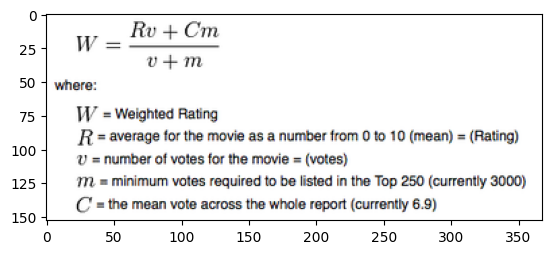

In [103]:
import matplotlib.pyplot as plt
img=plt.imread("/content/recomm_img.png")
plt.imshow(img)

In [104]:
v=df['vote_count']
R=df['vote_average']
C=df['vote_average'].mean()
m=df['vote_count'].quantile(0.70)

In [118]:
df['Weighted_average']=(R*v)+(C*m)/(v+m)
df.head()


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,...,spoken_languages,status,tagline,title_x,vote_average,vote_count,title_y,cast,crew,Weighted_average
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...",...,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de...",84960.285886
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...",...,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de...",31050.696625
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...",...,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de...",28136.501318
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...",...,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106,The Dark Knight Rises,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de...",69205.965392
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]",...,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124,John Carter,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de...",12957.708522


In [120]:
ranking=df.sort_values("Weighted_average",ascending = False)
ranking[["original_title","vote_count","Weighted_average","popularity"]].head(10)

,original_title,vote_count,Weighted_average,popularity
96,Inception,13752,111391.446951,167.583710
65,The Dark Knight,12002,98416.681296,187.322927
95,Interstellar,10867,88023.009185,724.247784
16,The Avengers,11776,87142.686441,144.448633
0,Avatar,11800,84960.285886,150.437577
788,Deadpool,10995,81363.305766,514.569956
287,Django Unchained,10099,78772.531419,82.121691
662,Fight Club,9413,78128.254168,146.757391
94,Guardians of the Galaxy,9742,76962.142880,481.098624
634,The Matrix,8907,70365.673056,104.309993


In [122]:
#plot it,recommendation based on movies in case of Weighted_average

In [123]:
import seaborn as sns

<Axes: xlabel='Weighted_average', ylabel='original_title'>

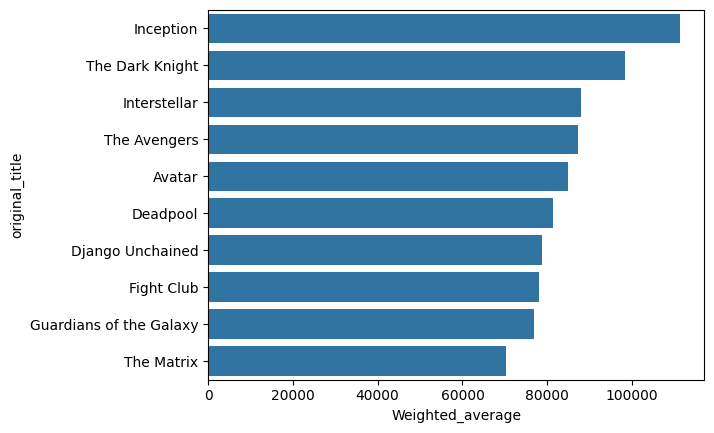

In [129]:
sns.barplot(y=ranking["original_title"].head(10),x=ranking["Weighted_average"].head(10),data=ranking.head(10))


In [132]:
popularity = df.sort_values('popularity',ascending = False)
popularity[['original_title','vote_count','Weighted_average','popularity']]

,original_title,vote_count,Weighted_average,popularity
546,Minions,4571,29255.087025,875.581305
95,Interstellar,10867,88023.009185,724.247784
788,Deadpool,10995,81363.305766,514.569956
94,Guardians of the Galaxy,9742,76962.142880,481.098624
127,Mad Max: Fury Road,9427,67874.753672,434.278564
...,...,...,...,...
4625,Midnight Cabaret,0,6.092172,0.001389
4118,Hum To Mohabbat Karega,0,6.092172,0.001186
4727,Penitentiary,8,45.209426,0.001117
3361,Alien Zone,3,18.060876,0.000372


<Axes: xlabel='Weighted_average', ylabel='original_title'>

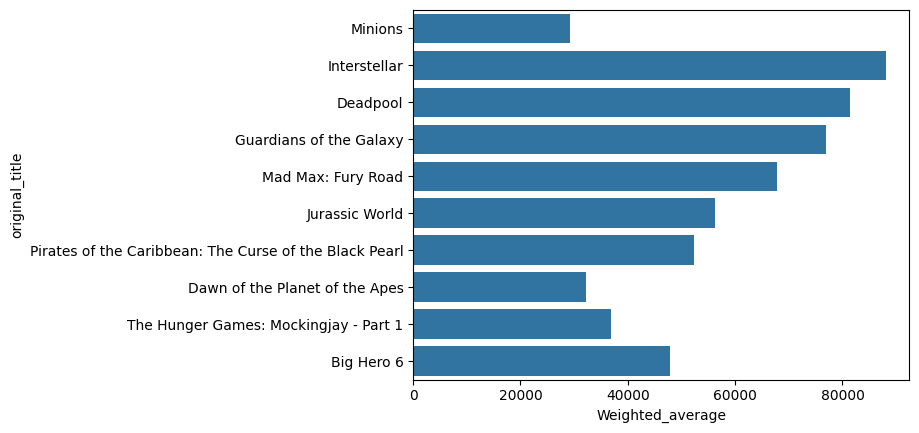

In [136]:
sns.barplot(y=popularity['original_title'].head(10),x=popularity['Weighted_average'].head(10),data=popularity.head(10))

In [138]:
#Graph are different according to weighted avg and Popularity, so inorder to solve that problem

In [139]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler()

In [141]:
scaler

MinMaxScaler()

In [142]:
df['popularity']=scaler.fit_transform(df[['popularity']])

In [143]:
df['Weighted_average']=scaler.fit_transform(df[["Weighted_average"]])

In [144]:
df['popularity']

0       0.171815
1       0.158846
2       0.122635
3       0.128272
4       0.050169
          ...   
4798    0.016298
4799    0.000734
4800    0.001650
4801    0.000979
4802    0.002204
Name: popularity, Length: 4803, dtype: float64

In [145]:
df['Weighted_average']

0       0.762705
1       0.278714
2       0.252550
3       0.621265
4       0.116278
          ...   
4798    0.014087
4799    0.000264
4800    0.000377
4801    0.000358
4802    0.000904
Name: Weighted_average, Length: 4803, dtype: float64

In [146]:
df.head()

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,...,spoken_languages,status,tagline,title_x,vote_average,vote_count,title_y,cast,crew,Weighted_average
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",0.171815,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...",...,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de...",0.762705
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",0.158846,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...",...,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de...",0.278714
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,0.122635,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...",...,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de...",0.252550
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,0.128272,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...",...,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106,The Dark Knight Rises,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de...",0.621265
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",0.050169,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]",...,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124,John Carter,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de...",0.116278


In [147]:
df['Score']=df['Weighted_average']*0.5 + df['popularity']*0.5

In [149]:
df.head()

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,...,status,tagline,title_x,vote_average,vote_count,title_y,cast,crew,Weighted_average,Score
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",0.171815,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...",...,Released,Enter the World of Pandora.,Avatar,7.2,11800,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de...",0.762705,0.467260
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",0.158846,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...",...,Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de...",0.278714,0.218780
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,0.122635,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...",...,Released,A Plan No One Escapes,Spectre,6.3,4466,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de...",0.252550,0.187593
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,0.128272,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...",...,Released,The Legend Ends,The Dark Knight Rises,7.6,9106,The Dark Knight Rises,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de...",0.621265,0.374769
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",0.050169,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]",...,Released,"Lost in our world, found in another.",John Carter,6.1,2124,John Carter,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de...",0.116278,0.083223


In [152]:
score_df=df.sort_values('Score',ascending = False)
score_df[['original_title','vote_count','Weighted_average','popularity','Score']]

,original_title,vote_count,Weighted_average,popularity,Score
95,Interstellar,10867,7.902019e-01,0.827162,8.086821e-01
788,Deadpool,10995,7.304121e-01,0.587690,6.590508e-01
546,Minions,4571,2.625929e-01,1.000000,6.312964e-01
94,Guardians of the Galaxy,9742,6.908992e-01,0.549462,6.201806e-01
96,Inception,13752,1.000000e+00,0.191397,5.956985e-01
...,...,...,...,...,...
4721,The Work and The Story,0,9.397688e-08,0.000003,1.410654e-06
4305,Down & Out With The Dolls,0,9.397688e-08,0.000003,1.409512e-06
4625,Midnight Cabaret,0,9.397688e-08,0.000002,8.401758e-07
4118,Hum To Mohabbat Karega,0,9.397688e-08,0.000001,7.242528e-07


<Axes: xlabel='Score', ylabel='original_title'>

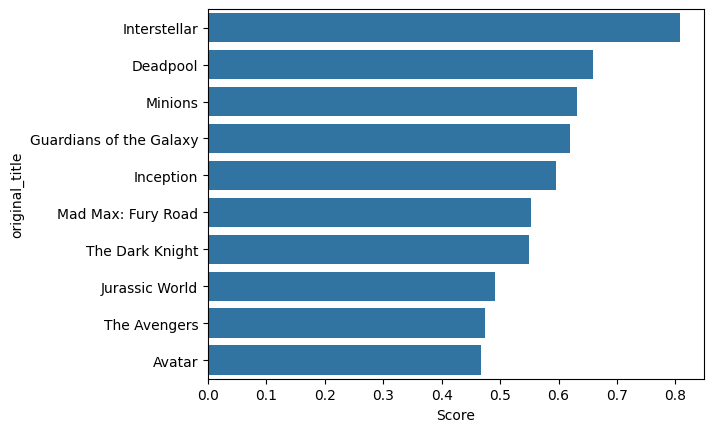

In [160]:
sns.barplot(y='original_title',x='Score',data=score_df.head(10))